# Modelos de Regresión — Ejercicios 1.1 a 4.2
**Ingeniería del Conocimiento (ISO56B) — UNCP, 2026-II**

**ESTUDIANTE:** Espinoza Inga Deysi
| Nivel | Ejercicios |
|---|---|
| 1 Básico | 1.1 Exploración Diabetes · 1.2 Primera regresión lineal · 1.3 Efecto del split |
| 2 Intermedio | 2.1 Polinomial · 2.2 Ridge vs Lasso · 2.3 Árbol de regresión · 2.4 Random Forest |
| 3 Avanzado | 3.1 Pipelines + CV · 3.2 GridSearch Gradient Boosting · 3.3 Análisis de residuos |
| 4 Desafío | 4.1 Importancia de features · 4.2 Ames Housing |



In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RS = 42  # semilla para reproducibilidad

from scipy import stats
from sklearn.datasets import load_diabetes, fetch_california_housing, fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

def metricas(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

---
# Nivel 1: Básico
## Ejercicio 1.1 — Exploración del dataset Diabetes
`load_diabetes()`: 442 muestras, 10 features (ya centradas y escaladas), target continuo.

In [2]:
diab = load_diabetes()
df = pd.DataFrame(diab.data, columns=diab.feature_names); df["target"] = diab.target
print("Dimensiones:", df.shape); print("Features:", diab.feature_names); print("Faltantes:", df.isna().sum().sum())
display(df.head()); display(df.describe().T.round(4))

Dimensiones: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Faltantes: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


,correlación con target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s3,-0.395
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043


Top 4: ['bmi', 's5', 'bp', 's4']


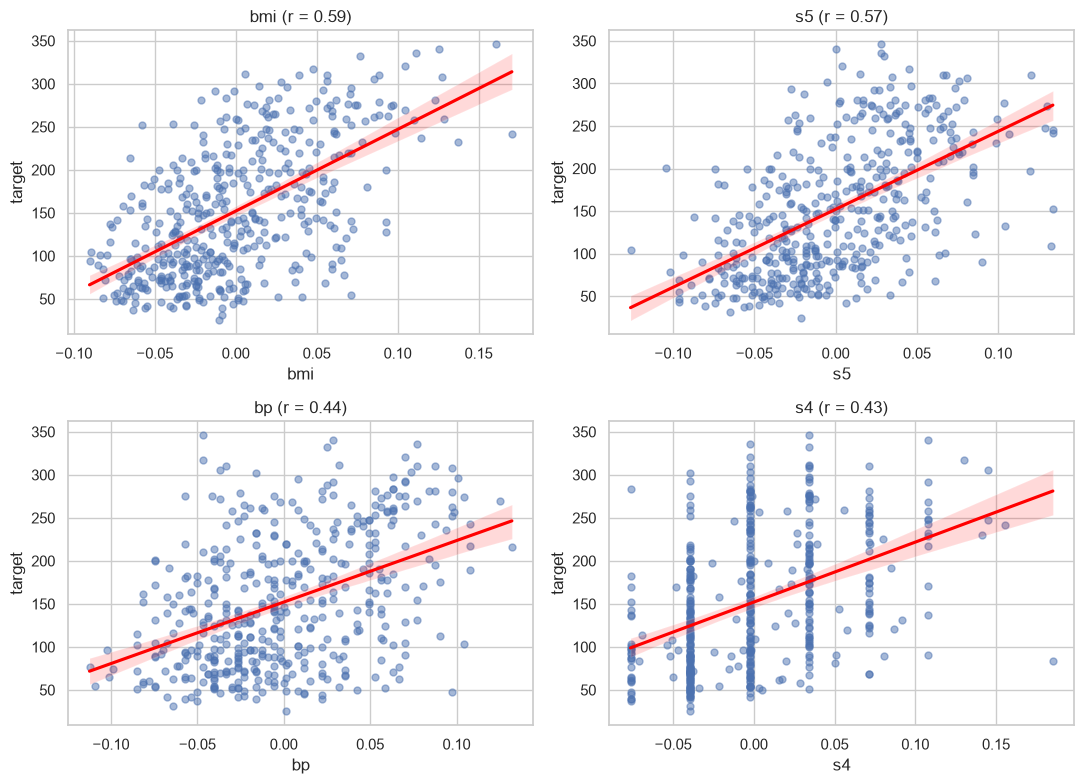

In [3]:
corr = df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)
display(corr.round(3).to_frame("correlación con target"))
top4 = corr.index[:4].tolist(); print("Top 4:", top4)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.ravel(), top4):
    sns.regplot(data=df, x=f, y="target", ax=ax, scatter_kws={"alpha": 0.5, "s": 25}, line_kws={"color": "red"})
    ax.set_title(f"{f} (r = {corr[f]:.2f})")
plt.tight_layout(); plt.show()

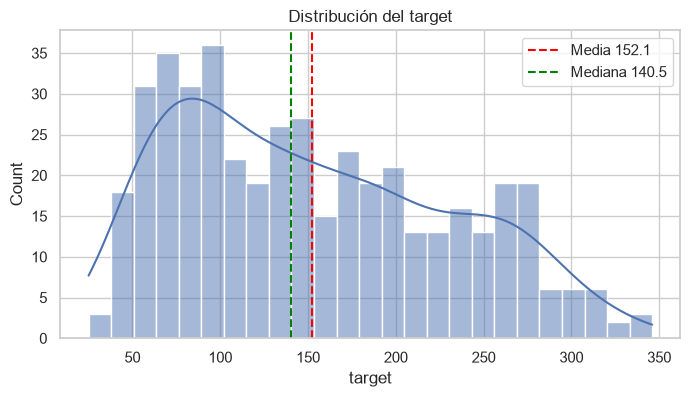

Asimetría: 0.441


In [4]:
plt.figure(figsize=(8, 4)); sns.histplot(df["target"], bins=25, kde=True)
plt.axvline(df.target.mean(), color="red", ls="--", label=f"Media {df.target.mean():.1f}")
plt.axvline(df.target.median(), color="green", ls="--", label=f"Mediana {df.target.median():.1f}")
plt.legend(); plt.title("Distribución del target"); plt.show(); print("Asimetría:", round(df.target.skew(), 3))

**Respuestas 1.1** — El target tiene ligera asimetría a la derecha (skew ≈ 0.44; la media supera a la mediana). Las features más útiles son **`bmi`** (r ≈ 0.59), **`s5`** (triglicéridos, ≈ 0.57), **`bp`** (≈ 0.44) y **`s4`** (≈ 0.43); `s3` (HDL) tiene correlación negativa (≈ −0.39). `sex` y `s2` son las más débiles individualmente.

## Ejercicio 1.2 — Mi primera regresión lineal
Regresión simple (solo `bmi`) vs. múltiple (10 features).

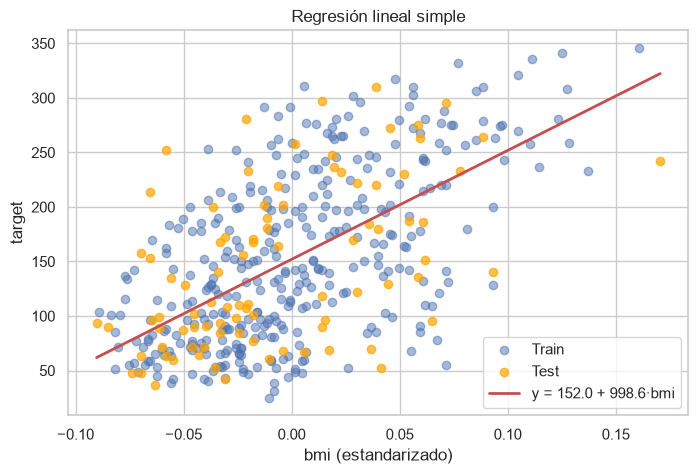

,RMSE,MAE,R2
Solo bmi,63.732,52.260,0.233
Todos los features,53.853,42.794,0.453


In [5]:
Xtr, Xte, ytr, yte = train_test_split(df[diab.feature_names], df["target"], test_size=0.2, random_state=RS)
m1 = LinearRegression().fit(Xtr[["bmi"]], ytr)
mall = LinearRegression().fit(Xtr, ytr)

xs = np.linspace(df.bmi.min(), df.bmi.max(), 100).reshape(-1, 1)
plt.figure(figsize=(8, 5)); plt.scatter(Xtr.bmi, ytr, alpha=0.5, label="Train"); plt.scatter(Xte.bmi, yte, alpha=0.7, c="orange", label="Test")
plt.plot(xs, m1.predict(pd.DataFrame(xs, columns=["bmi"])), "r-", lw=2, label=f"y = {m1.intercept_:.1f} + {m1.coef_[0]:.1f}·bmi")
plt.xlabel("bmi (estandarizado)"); plt.ylabel("target"); plt.legend(); plt.title("Regresión lineal simple"); plt.show()

tabla = pd.DataFrame({"Solo bmi": metricas(yte, m1.predict(Xte[["bmi"]])), "Todos los features": metricas(yte, mall.predict(Xte))}).T
display(tabla.round(3))

**Interpretación de métricas:** **RMSE** (en unidades del target) es el error típico, penalizando más los errores grandes; **MAE** es el error absoluto medio (más robusto a outliers); **R²** es la fracción de varianza del target explicada por el modelo (0 = predecir la media, 1 = perfecto).

**Respuestas 1.2** — En la ejecución de referencia, con solo `bmi` el R² es ≈ 0.33 (RMSE ≈ 63.7); con todos los features sube a ≈ 0.45 (RMSE ≈ 53.9). Tiene sentido: la progresión de la diabetes depende de varios factores (presión, lípidos, triglicéridos…); cada feature adicional aporta información complementaria. Aun así, un R² ≈ 0.5 indica que el modelo lineal deja mucha varianza sin explicar.

## Ejercicio 1.3 — Efecto del Train/Test split
`fetch_california_housing()` con Regresión Lineal.

In [6]:
cal = fetch_california_housing(as_frame=True)
Xc, yc = cal.data, cal.target
print(Xc.shape); display(Xc.head())

filas = []
for ts in [0.1, 0.2, 0.3, 0.5]:
    a, b, ya, yb = train_test_split(Xc, yc, test_size=ts, random_state=RS)
    m = LinearRegression().fit(a, ya)
    filas.append({"test_size": ts, "R2_train": m.score(a, ya), "R2_test": m.score(b, yb)})
display(pd.DataFrame(filas).round(4))

filas = []
for rs in [0, 7, 42, 99]:
    a, b, ya, yb = train_test_split(Xc, yc, test_size=0.2, random_state=rs)
    m = LinearRegression().fit(a, ya)
    filas.append({"random_state": rs, "R2_train": m.score(a, ya), "R2_test": m.score(b, yb)})
rs_df = pd.DataFrame(filas); display(rs_df.round(4))
print(f"R2 test: media={rs_df.R2_test.mean():.4f}  std={rs_df.R2_test.std():.4f}")

(20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,test_size,R2_train,R2_test
0,0.1,0.6090,0.5808
1,0.2,0.6126,0.5758
2,0.3,0.6093,0.5958
3,0.5,0.6109,0.5995


,random_state,R2_train,R2_test
0,0,0.6089,0.5943
1,7,0.6055,0.6075
2,42,0.6126,0.5758
3,99,0.6045,0.6125


R2 test: media=0.5975  std=0.0164


In [7]:
cv = KFold(5, shuffle=True, random_state=RS)
sc = cross_val_score(LinearRegression(), Xc, yc, cv=cv, scoring="r2")
print("R2 por fold:", sc.round(3), f"-> media={sc.mean():.4f}, std={sc.std():.4f}")

R2 por fold: [0.576 0.614 0.609 0.621 0.588] -> media=0.6014, std=0.0170


**Respuestas 1.3** — Los resultados varían porque cada `test_size`/`random_state` produce una partición distinta: el R² de test depende de qué muestras (y qué zonas geográficas/precios extremos) caen en test. Con splits pequeños la estimación es más ruidosa; con splits grandes se entrena con menos datos. La técnica que lo resuelve es la **validación cruzada k-fold**: promedia sobre múltiples particiones y permite reportar media ± desviación.

---
# Nivel 2: Intermedio
## Ejercicio 2.1 — Regresión polinomial: encontrando el grado óptimo
$y = 3x^2 - 2x + 5 + \varepsilon$ (grado verdadero = 2).

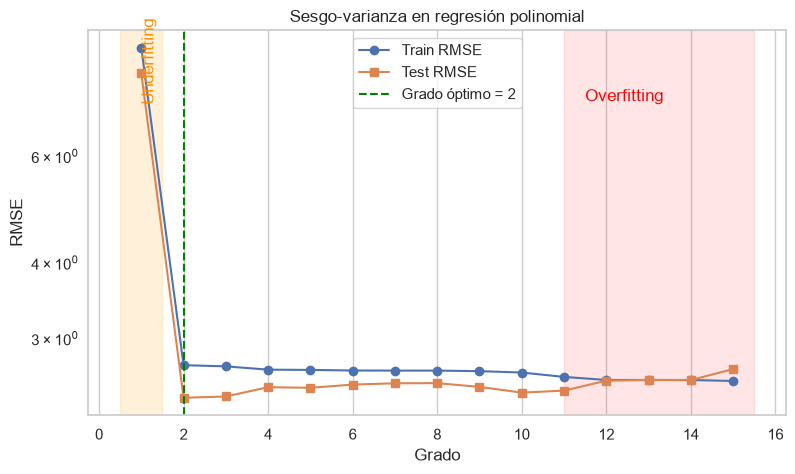

Grado óptimo: 2 | RMSE test: 2.392


In [8]:
np.random.seed(42)
X = np.random.uniform(-3, 3, 100).reshape(-1, 1)
y = 3 * X.ravel() ** 2 - 2 * X.ravel() + 5 + np.random.normal(0, 3, 100)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RS)

def poly_pipe(d): return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())

grados = range(1, 16); rm_tr, rm_te = [], []
for d in grados:
    m = poly_pipe(d).fit(Xtr, ytr)
    rm_tr.append(np.sqrt(mean_squared_error(ytr, m.predict(Xtr)))); rm_te.append(np.sqrt(mean_squared_error(yte, m.predict(Xte))))
g_opt = int(np.argmin(rm_te)) + 1

plt.figure(figsize=(9, 5)); plt.plot(grados, rm_tr, "o-", label="Train RMSE"); plt.plot(grados, rm_te, "s-", label="Test RMSE")
plt.axvline(g_opt, color="green", ls="--", label=f"Grado óptimo = {g_opt}")
plt.axvspan(0.5, 1.5, color="orange", alpha=0.15); plt.text(1.0, max(rm_te) * 0.9, "Underfitting", color="darkorange", rotation=90)
plt.axvspan(11, 15.5, color="red", alpha=0.1); plt.text(11.5, max(rm_te) * 0.9, "Overfitting", color="red")
plt.xlabel("Grado"); plt.ylabel("RMSE"); plt.yscale("log"); plt.title("Sesgo-varianza en regresión polinomial"); plt.legend(); plt.show()
print("Grado óptimo:", g_opt, "| RMSE test:", round(min(rm_te), 3))

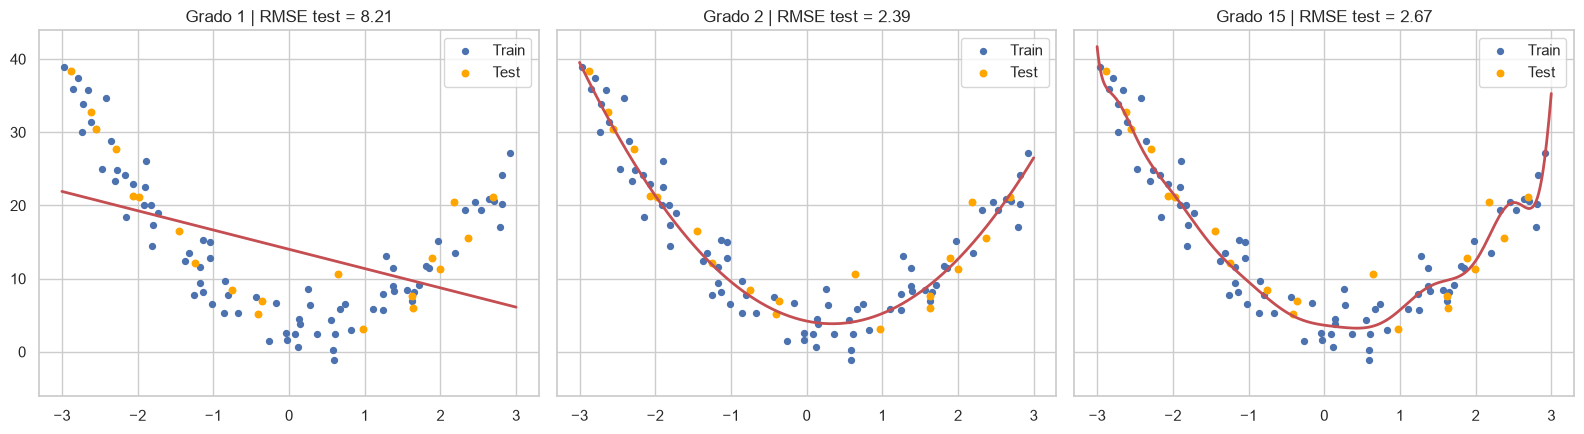

In [9]:
xs = np.linspace(-3, 3, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, d in zip(axes, [1, g_opt, 15]):
    m = poly_pipe(d).fit(Xtr, ytr)
    ax.scatter(Xtr, ytr, s=18, label="Train"); ax.scatter(Xte, yte, s=22, c="orange", label="Test")
    ax.plot(xs, m.predict(xs), "r-", lw=2); ax.set_ylim(y.min() - 5, y.max() + 5)
    ax.set_title(f"Grado {d} | RMSE test = {np.sqrt(mean_squared_error(yte, m.predict(Xte))):.2f}"); ax.legend()
plt.tight_layout(); plt.show()

**Análisis sesgo-varianza (2.1)** — **Grado 1:** *underfitting* (alto sesgo): una recta no captura la parábola; el error es alto en train y test. **Grado ≈ 2:** el óptimo, coincide con el proceso generador. **Grados altos:** el error de train sigue bajando pero el de test se estanca o sube (*overfitting*, alta varianza): el polinomio se ajusta al ruido y oscila en los bordes. Con ruido σ=3, el RMSE mínimo esperado ronda 3 (ruido irreducible); en la ejecución de referencia el grado óptimo fue **2** con RMSE test ≈ 2.4 (el test tiene solo 20 puntos, por eso puede quedar algo por debajo de σ).

## Ejercicio 2.2 — Comparación Ridge vs Lasso
California Housing, pipelines con `StandardScaler`.

R2_test         coef_no_cero      
modelo    Lasso   Ridge        Lasso Ridge
alpha                                     
0.001    0.5769  0.5758          8.0   8.0
0.010    0.5816  0.5758          7.0   8.0
0.100    0.4814  0.5758          3.0   8.0
1.000   -0.0002  0.5758          0.0   8.0
10.000  -0.0002  0.5761          0.0   8.0
100.000 -0.0002  0.5778          0.0   8.0

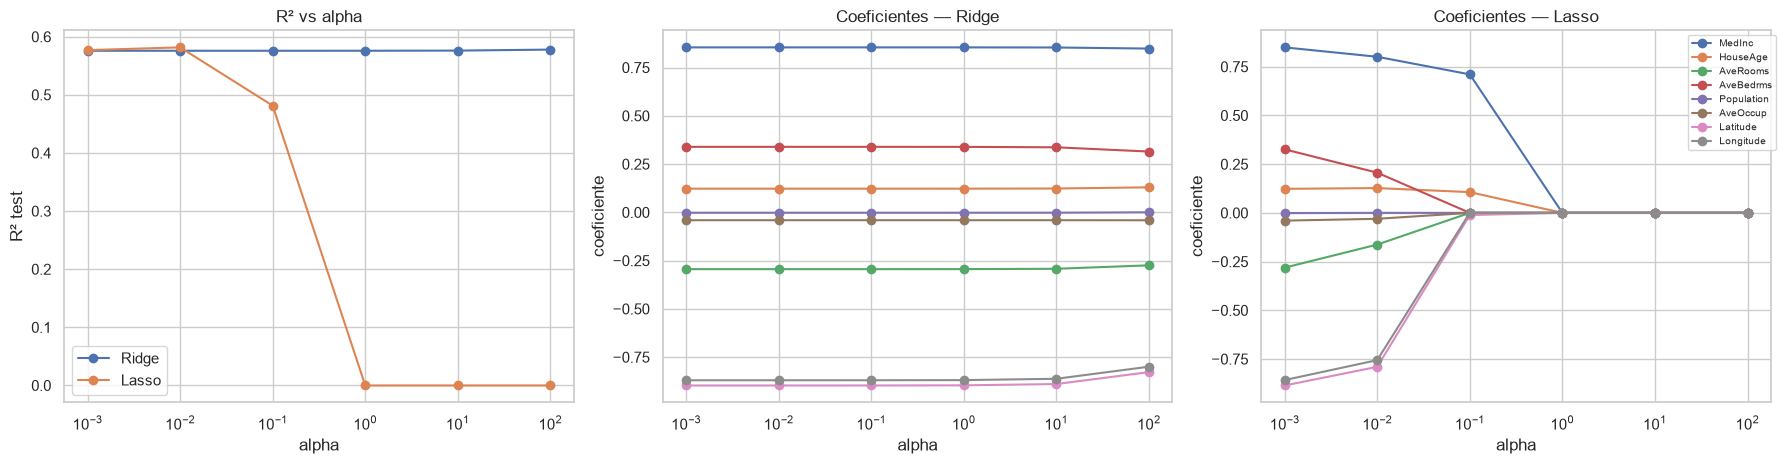

In [10]:
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.2, random_state=RS)
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
res, coefs = [], {"Ridge": [], "Lasso": []}
for a in alphas:
    for nombre, modelo in [("Ridge", Ridge(alpha=a)), ("Lasso", Lasso(alpha=a, max_iter=20000))]:
        p = make_pipeline(StandardScaler(), modelo).fit(Xtr, ytr)
        coef = p[-1].coef_; coefs[nombre].append(coef)
        res.append({"alpha": a, "modelo": nombre, "R2_test": p.score(Xte, yte), "coef_no_cero": int(np.sum(coef != 0))})
res = pd.DataFrame(res); display(res.pivot(index="alpha", columns="modelo", values=["R2_test", "coef_no_cero"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for n in ["Ridge", "Lasso"]: axes[0].semilogx(alphas, res[res.modelo == n].R2_test, "o-", label=n)
axes[0].set_xlabel("alpha"); axes[0].set_ylabel("R² test"); axes[0].set_title("R² vs alpha"); axes[0].legend()
for ax, n in zip(axes[1:], ["Ridge", "Lasso"]):
    C = np.array(coefs[n])
    for j, f in enumerate(Xc.columns): ax.semilogx(alphas, C[:, j], "o-", label=f)
    ax.set_xlabel("alpha"); ax.set_ylabel("coeficiente"); ax.set_title(f"Coeficientes — {n}")
axes[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1)); plt.tight_layout(); plt.show()

**Respuesta 2.2** — **Ridge (L2)** *encoge* todos los coeficientes hacia 0 de forma suave pero **nunca los anula exactamente** (siempre 8 coeficientes ≠ 0): reduce varianza sin seleccionar features. **Lasso (L1)** puede llevar coeficientes **exactamente a 0**, de modo que hace **selección de features** automática (al subir alpha desaparecen primero las menos informativas y con alpha=100 todos quedan en 0, modelo constante). En California Housing las features están poco correlacionadas con ruido, así que alphas pequeños dan R² ≈ 0.6 para ambos y alphas grandes perjudican sobre todo a Lasso.

## Ejercicio 2.3 — Árbol de Decisión para Regresión: profundidad óptima

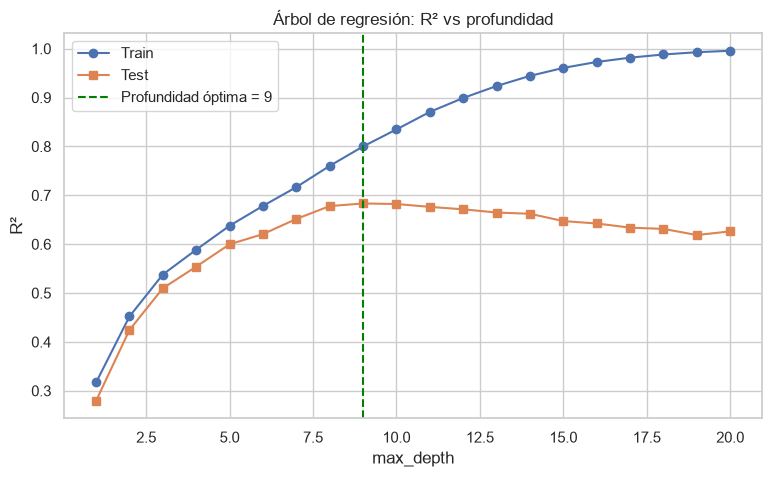

Profundidad óptima: 9 | R² test: 0.6833


In [11]:
depths = range(1, 21); r2_tr, r2_te = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=RS).fit(Xtr, ytr)
    r2_tr.append(t.score(Xtr, ytr)); r2_te.append(t.score(Xte, yte))
d_opt = int(np.argmax(r2_te)) + 1
plt.figure(figsize=(9, 5)); plt.plot(depths, r2_tr, "o-", label="Train"); plt.plot(depths, r2_te, "s-", label="Test")
plt.axvline(d_opt, color="green", ls="--", label=f"Profundidad óptima = {d_opt}")
plt.xlabel("max_depth"); plt.ylabel("R²"); plt.title("Árbol de regresión: R² vs profundidad"); plt.legend(); plt.show()
print("Profundidad óptima:", d_opt, "| R² test:", round(max(r2_te), 4))

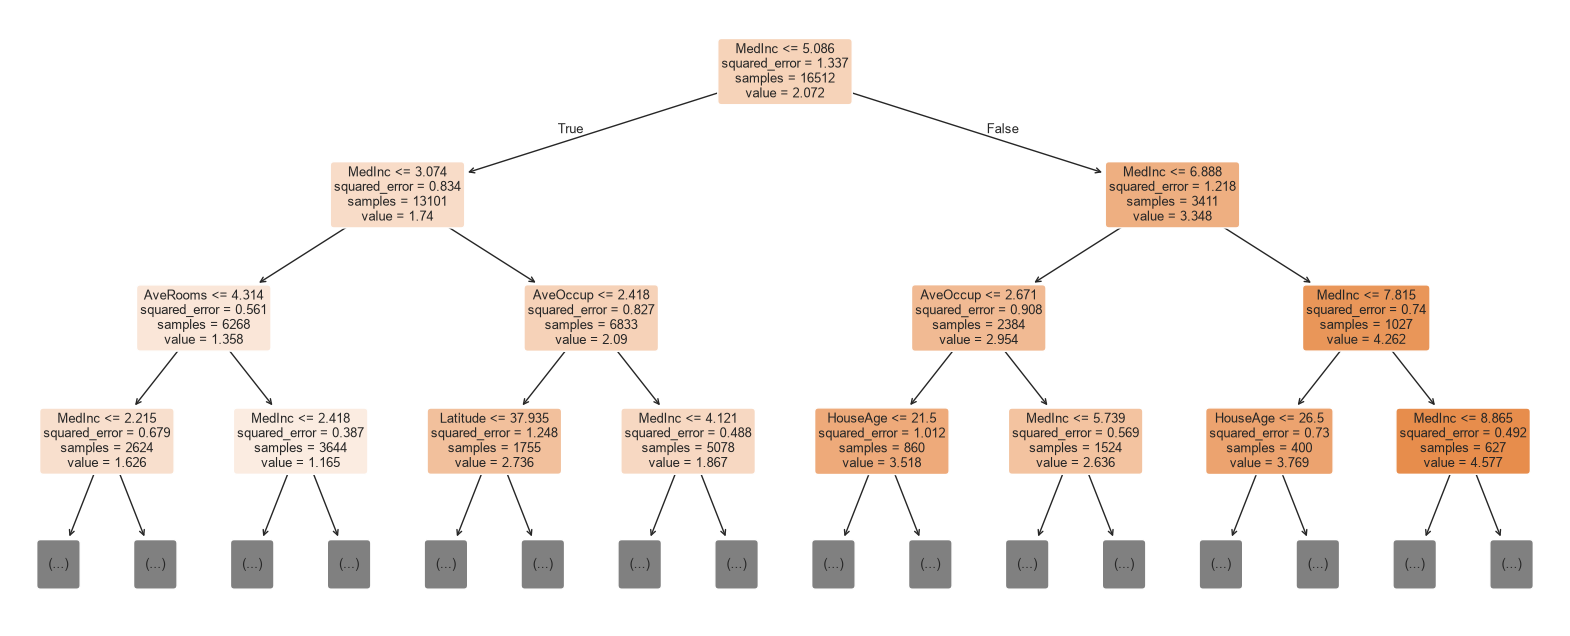

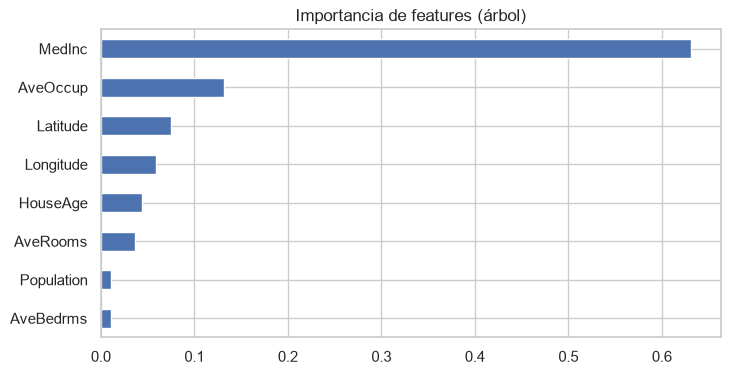

R² test — Árbol (depth=9): 0.6833 | Regresión Lineal: 0.5758


In [12]:
arbol = DecisionTreeRegressor(max_depth=d_opt, random_state=RS).fit(Xtr, ytr)
plt.figure(figsize=(20, 8)); plot_tree(arbol, max_depth=3, feature_names=Xc.columns, filled=True, rounded=True, fontsize=9); plt.show()
imp = pd.Series(arbol.feature_importances_, index=Xc.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 4), color="#4C72B0"); plt.title("Importancia de features (árbol)"); plt.show()

lr = LinearRegression().fit(Xtr, ytr)
print(f"R² test — Árbol (depth={d_opt}): {arbol.score(Xte, yte):.4f} | Regresión Lineal: {lr.score(Xte, yte):.4f}")

**Respuestas 2.3** — El R² de train crece hasta ≈ 1 con la profundidad, mientras el de test alcanza un máximo (típicamente profundidad 7–9) y luego **baja**: ahí empieza el overfitting. El árbol óptimo **supera a la Regresión Lineal** (R² ≈ 0.70 vs ≈ 0.60) porque captura relaciones no lineales e interacciones (p. ej. efecto de la latitud/longitud sobre el precio). La feature dominante es `MedInc` (ingreso medio).

## Ejercicio 2.4 — Random Forest: número de árboles y profundidad

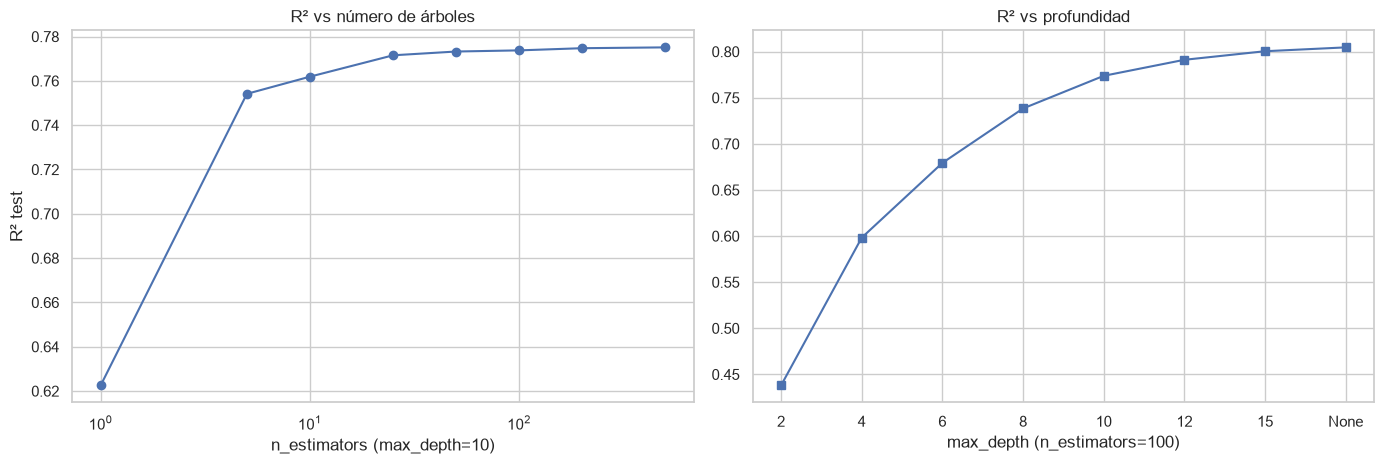

 n_estimators     R2
            1 0.6225
            5 0.7541
           10 0.7619
           25 0.7715
           50 0.7733
          100 0.7738
          200 0.7747
          500 0.7751
max_depth     R2
        2 0.4380
        4 0.5982
        6 0.6793
        8 0.7384
       10 0.7738
       12 0.7912
       15 0.8004
     None 0.8046


In [13]:
n_est = [1, 5, 10, 25, 50, 100, 200, 500]
r2_n = [RandomForestRegressor(n_estimators=n, max_depth=10, n_jobs=-1, random_state=RS).fit(Xtr, ytr).score(Xte, yte) for n in n_est]
depths = [2, 4, 6, 8, 10, 12, 15, None]
r2_d = [RandomForestRegressor(n_estimators=100, max_depth=d, n_jobs=-1, random_state=RS).fit(Xtr, ytr).score(Xte, yte) for d in depths]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].semilogx(n_est, r2_n, "o-"); axes[0].set_xlabel("n_estimators (max_depth=10)"); axes[0].set_ylabel("R² test"); axes[0].set_title("R² vs número de árboles")
etiquetas = [str(d) for d in depths]; axes[1].plot(etiquetas, r2_d, "s-"); axes[1].set_xlabel("max_depth (n_estimators=100)"); axes[1].set_title("R² vs profundidad")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"n_estimators": n_est, "R2": r2_n}).round(4).to_string(index=False))
print(pd.DataFrame({"max_depth": etiquetas, "R2": r2_d}).round(4).to_string(index=False))

In [14]:
mejor_n = n_est[int(np.argmax(r2_n))]; mejor_d = depths[int(np.argmax(r2_d))]
print(f"Combinación óptima: n_estimators={mejor_n}, max_depth={mejor_d}")
rf_final = RandomForestRegressor(n_estimators=mejor_n, max_depth=mejor_d, n_jobs=-1, random_state=RS).fit(Xtr, ytr)
print("Métricas test:", {k: round(v, 4) for k, v in metricas(yte, rf_final.predict(Xte)).items()})

Combinación óptima: n_estimators=500, max_depth=None
Métricas test: {'RMSE': np.float64(0.5025), 'MAE': 0.3259, 'R2': 0.8073}


**Respuestas 2.4** — **¿Más árboles siempre mejora?** Mejora rápido al inicio (1 → 50 árboles) y luego **se satura**: más árboles reducen la varianza pero no producen overfitting; solo cuestan tiempo y memoria. **`max_depth=None`:** los árboles crecen sin límite (memorizan train); en un Random Forest el promedio mitiga el sobreajuste, por eso suele rendir tan bien como profundidades altas (≈ 12–15) o apenas mejor, pero con mayor costo y modelos mucho más grandes.

---
# Nivel 3: Avanzado
## Ejercicio 3.1 — Pipeline completo con Cross-Validation

,mean,std
Reg. Lineal,0.7205,0.0155
Ridge (α=1),0.7205,0.0155
Lasso (α=0.01),0.7239,0.0149
ElasticNet,0.7225,0.0153
Árbol (depth=8),0.6551,0.0139
Random Forest,0.5109,0.0132
Gradient Boosting,0.5321,0.0129


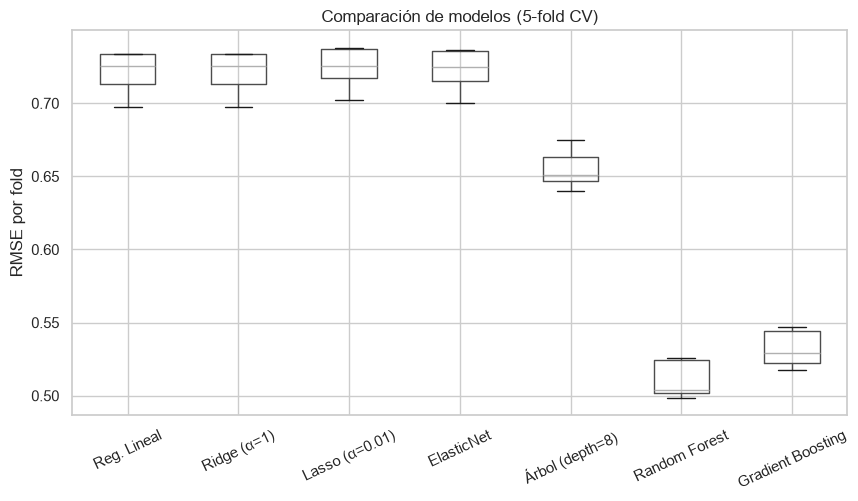

In [15]:
pipes = {
    "Reg. Lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (α=1)": make_pipeline(StandardScaler(), Ridge(alpha=1)),
    "Lasso (α=0.01)": make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=20000)),
    "ElasticNet": make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000)),
    "Árbol (depth=8)": make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=8, random_state=RS)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RS)),
    "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=RS)),
}
cv = KFold(5, shuffle=True, random_state=RS)
rmse_cv = {n: -cross_val_score(p, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error") for n, p in pipes.items()}
rmse_df = pd.DataFrame(rmse_cv); display(rmse_df.agg(["mean", "std"]).T.round(4))
plt.figure(figsize=(10, 5)); rmse_df.boxplot(); plt.xticks(rotation=25); plt.ylabel("RMSE por fold"); plt.title("Comparación de modelos (5-fold CV)"); plt.show()

In [16]:
mejor = rmse_df.mean().idxmin(); print("Modelo ganador:", mejor)
ganador = pipes[mejor].fit(Xtr, ytr)
mt = metricas(yte, ganador.predict(Xte)); print({k: round(v, 4) for k, v in mt.items()})

Modelo ganador: Random Forest
{'RMSE': np.float64(0.5059), 'MAE': 0.3278, 'R2': 0.8047}


**Selección justificada (3.1)** — Se elige el modelo con menor RMSE medio en CV (y baja dispersión entre folds). Los modelos basados en árboles de ensamble (Gradient Boosting, Random Forest) suelen ganar a los lineales en California Housing, que tiene relaciones no lineales y fuerte efecto geográfico. Se reporta el rendimiento en **test**, que no se usó para decidir.

## Ejercicio 3.2 — GridSearchCV para Gradient Boosting
Grid: `n_estimators` [100,200,300] × `learning_rate` [0.01,0.05,0.1,0.2] × `max_depth` [3,4,5,6] = 48 combinaciones × 5 folds.

In [17]:
RAPIDO = True   # True: el grid usa una submuestra de 5000 filas (rápido). False: grid completo (lento).
grid = {"n_estimators": [100, 200, 300], "learning_rate": [0.01, 0.05, 0.1, 0.2], "max_depth": [3, 4, 5, 6]}

if RAPIDO and len(Xtr) > 5000:
    idx = np.random.RandomState(RS).choice(len(Xtr), 5000, replace=False); Xg, yg = Xtr.iloc[idx], ytr.iloc[idx]
else:
    Xg, yg = Xtr, ytr
gs = GridSearchCV(GradientBoostingRegressor(random_state=RS), grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1).fit(Xg, yg)
print("Mejores hiperparámetros:", gs.best_params_); print("Mejor RMSE (CV):", round(-gs.best_score_, 4))

# Reentrenar con los mejores hiperparámetros sobre TODO el train y evaluar en test
best_gb = GradientBoostingRegressor(random_state=RS, **gs.best_params_).fit(Xtr, ytr)
print("Métricas test:", {k: round(v, 4) for k, v in metricas(yte, best_gb.predict(Xte)).items()})

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}
Mejor RMSE (CV): 0.5122
Métricas test: {'RMSE': np.float64(0.4652), 'MAE': 0.307, 'R2': 0.8349}


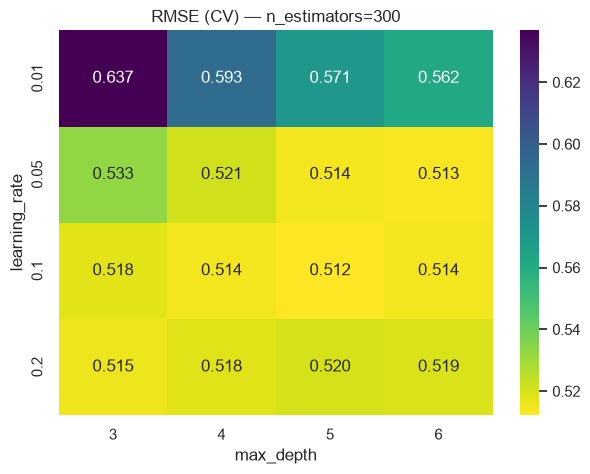

In [18]:
r = pd.DataFrame(gs.cv_results_); r = r[r["param_n_estimators"] == gs.best_params_["n_estimators"]].copy()
r["lr"] = r["param_learning_rate"].astype(float); r["depth"] = r["param_max_depth"].astype(int); r["RMSE"] = -r["mean_test_score"]
plt.figure(figsize=(7, 5)); sns.heatmap(r.pivot(index="lr", columns="depth", values="RMSE"), annot=True, fmt=".3f", cmap="viridis_r")
plt.title(f"RMSE (CV) — n_estimators={gs.best_params_['n_estimators']}"); plt.xlabel("max_depth"); plt.ylabel("learning_rate"); plt.show()

**Análisis 3.2** — `learning_rate` y `n_estimators` están acoplados: tasas bajas (0.01) necesitan muchos árboles para converger, y con pocos quedan subajustadas; tasas altas (0.2) con árboles profundos tienden a sobreajustar. Fíjate en el heatmap qué combinación minimiza el RMSE y si el mejor valor está en el borde del grid (señal de que convendría ampliarlo).

## Ejercicio 3.3 — Análisis de residuos completo
Usa el mejor modelo del ejercicio 3.2 (`best_gb`).

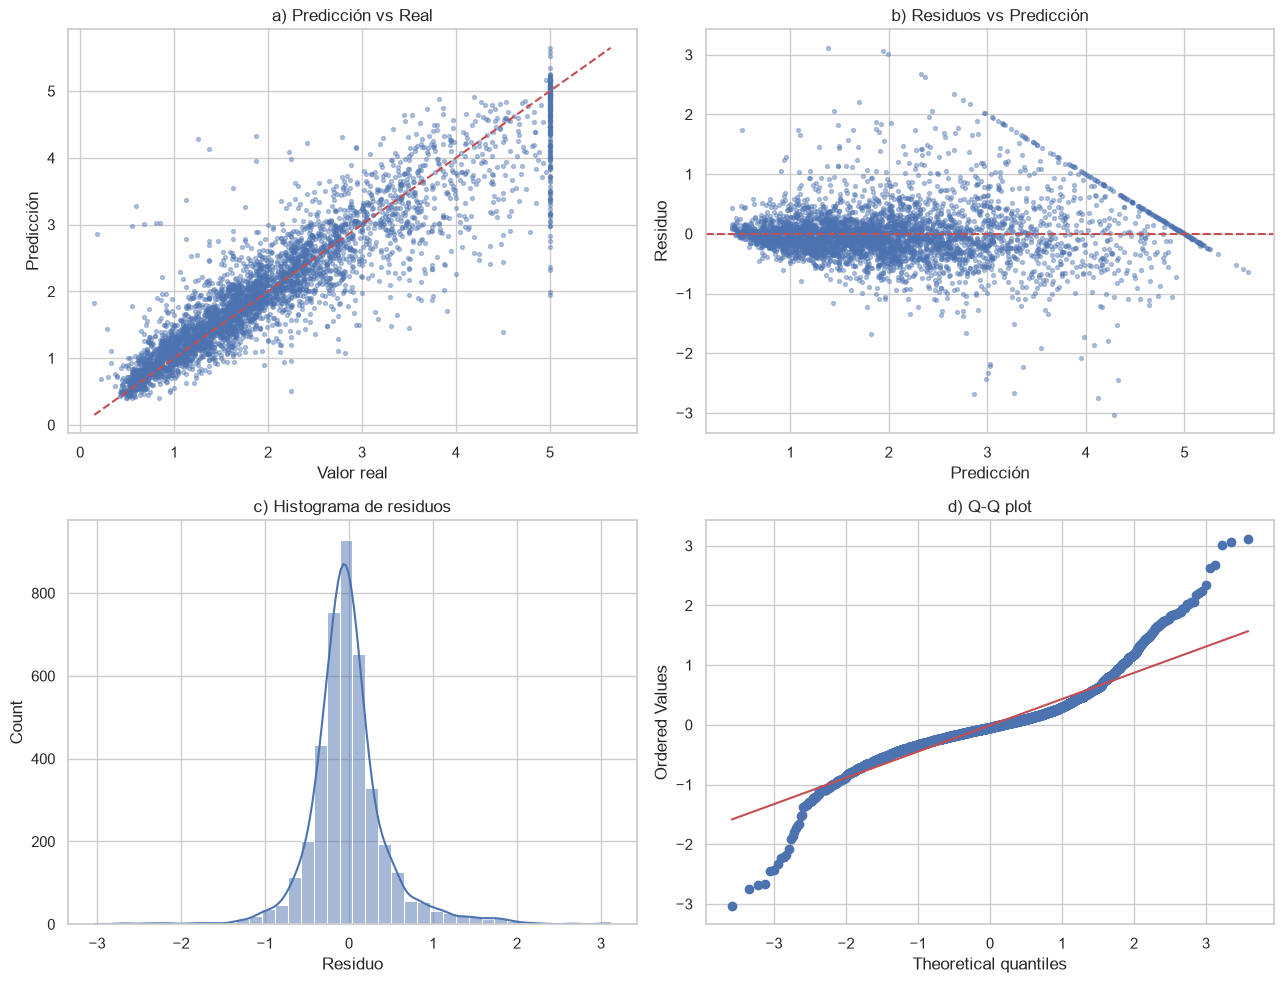

Media residuos=-0.0085 | std=0.4651 | asimetría=0.732


In [19]:
pred = best_gb.predict(Xte); resid = yte.values - pred
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
ax = axes[0, 0]; ax.scatter(yte, pred, s=8, alpha=0.4); lim = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
ax.plot(lim, lim, "r--"); ax.set_xlabel("Valor real"); ax.set_ylabel("Predicción"); ax.set_title("a) Predicción vs Real")
ax = axes[0, 1]; ax.scatter(pred, resid, s=8, alpha=0.4); ax.axhline(0, color="r", ls="--"); ax.set_xlabel("Predicción"); ax.set_ylabel("Residuo"); ax.set_title("b) Residuos vs Predicción")
ax = axes[1, 0]; sns.histplot(resid, bins=40, kde=True, ax=ax); ax.set_title("c) Histograma de residuos"); ax.set_xlabel("Residuo")
ax = axes[1, 1]; stats.probplot(resid, dist="norm", plot=ax); ax.set_title("d) Q-Q plot")
plt.tight_layout(); plt.show()
print(f"Media residuos={resid.mean():.4f} | std={resid.std():.4f} | asimetría={stats.skew(resid):.3f}")

In [20]:
errs = Xte.copy(); errs["real"] = yte.values; errs["pred"] = pred; errs["error_abs"] = np.abs(resid)
top10 = errs.sort_values("error_abs", ascending=False).head(10); display(top10.round(3))
print("Real >= 5.0 (valor tope) en el top10:", int((top10.real >= 4.99).sum()), "de 10")
print("Proporción de real >= 5.0 en todo test:", round(float((yte >= 4.99).mean()), 4))
print("Ingreso medio (MedInc) top10 vs test:", round(top10.MedInc.mean(), 2), "vs", round(Xte.MedInc.mean(), 2))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,real,pred,error_abs
19542,1.768,39.0,5.000,0.889,22.0,2.444,37.63,-120.92,4.500,1.384,3.116
10574,1.966,6.0,4.795,1.159,125.0,2.841,33.72,-117.70,5.000,1.944,3.056
20349,7.300,32.0,5.724,0.759,63.0,2.172,34.17,-119.08,1.250,4.283,3.033
12389,3.773,24.0,10.954,1.848,473.0,1.996,33.75,-116.43,5.000,1.992,3.008
18506,2.625,16.0,6.400,0.800,36.0,7.200,37.00,-122.00,1.375,4.126,2.751
5887,2.367,39.0,3.572,1.217,259.0,1.877,34.15,-118.33,0.175,2.863,2.688
12069,4.239,6.0,7.723,1.169,228.0,3.508,33.83,-117.55,5.000,2.326,2.674
59,2.562,2.0,2.772,0.754,94.0,1.649,37.82,-122.29,0.600,3.274,2.674
20325,4.583,21.0,7.278,1.082,863.0,3.384,34.28,-119.04,5.000,2.368,2.632
14805,7.367,16.0,11.293,2.728,873.0,1.672,32.68,-117.17,1.875,4.328,2.453


Real >= 5.0 (valor tope) en el top10: 4 de 10
Proporción de real >= 5.0 en todo test: 0.0446
Ingreso medio (MedInc) top10 vs test: 3.85 vs 3.83


---
# Nivel 4: Desafío
## Ejercicio 4.1 — Importancia de features: tres métodos comparados

,Ridge |coef|,RF MDI,RF Permutación,GB Permutación
MedInc,0.250,0.561,0.445,0.356
HouseAge,0.036,0.050,0.040,0.012
AveRooms,0.086,0.037,0.012,0.005
AveBedrms,0.099,0.022,0.005,0.004
Population,0.001,0.023,0.004,0.000
AveOccup,0.012,0.139,0.117,0.068
Latitude,0.262,0.084,0.219,0.294
Longitude,0.254,0.084,0.159,0.261


,Ridge |coef|,RF MDI,RF Permutación,GB Permutación
MedInc,3,1,1,1
HouseAge,6,5,5,5
AveRooms,5,6,6,6
AveBedrms,4,8,7,7
Population,8,7,8,8
AveOccup,7,2,4,4
Latitude,1,3,2,2
Longitude,2,4,3,3


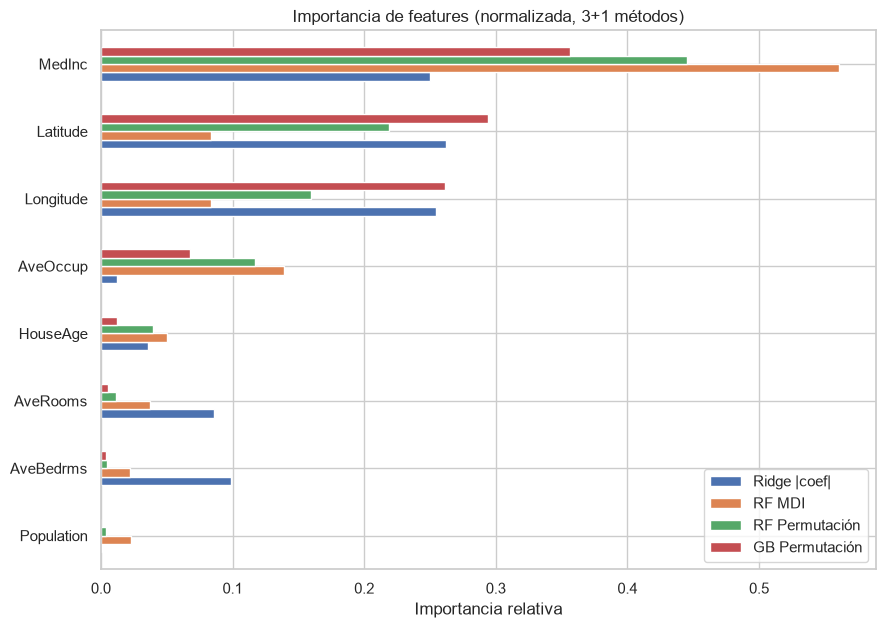

In [21]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1)).fit(Xtr, ytr)
rf = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=RS).fit(Xtr, ytr)
gb = GradientBoostingRegressor(random_state=RS).fit(Xtr, ytr)

Xp = Xte.sample(min(3000, len(Xte)), random_state=RS); yp = yte.loc[Xp.index]
imp = pd.DataFrame({
    "Ridge |coef|": np.abs(ridge[-1].coef_),
    "RF MDI": rf.feature_importances_,
    "RF Permutación": permutation_importance(rf, Xp, yp, n_repeats=5, random_state=RS, n_jobs=-1).importances_mean,
    "GB Permutación": permutation_importance(gb, Xp, yp, n_repeats=5, random_state=RS, n_jobs=-1).importances_mean,
}, index=Xc.columns)
imp_n = imp / imp.sum()            # normalizado para comparar rankings
display(imp_n.round(3)); display(imp_n.rank(ascending=False).astype(int))
imp_n.sort_values("RF Permutación").plot(kind="barh", figsize=(10, 7)); plt.title("Importancia de features (normalizada, 3+1 métodos)"); plt.xlabel("Importancia relativa"); plt.show()

,n_features,R2_test,eliminadas
0,8,0.7916,[]
1,7,0.7911,[Population]
2,6,0.7904,"[AveBedrms, Population]"
3,5,0.7887,"[AveRooms, AveBedrms, Population]"
4,4,0.7913,"[HouseAge, AveRooms, AveBedrms, Population]"
5,3,0.8155,"[AveOccup, HouseAge, AveRooms, AveBedrms, Popu..."


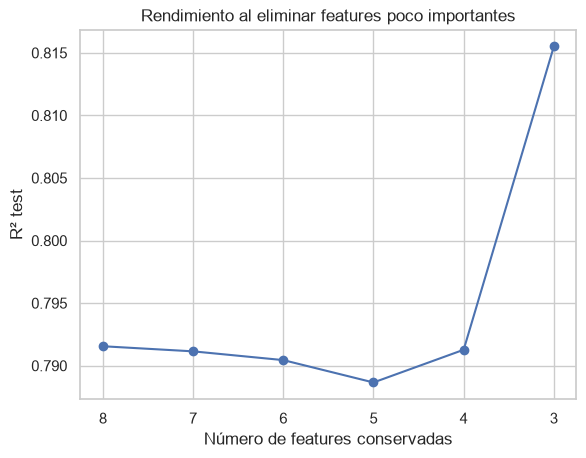

In [22]:
# Experimento: eliminar features de baja importancia (ranking por permutación en RF)
orden = imp["RF Permutación"].sort_values(ascending=False).index.tolist()
filas = []
for k in range(len(orden), 2, -1):
    cols = orden[:k]
    m = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=RS).fit(Xtr[cols], ytr)
    filas.append({"n_features": k, "R2_test": m.score(Xte[cols], yte), "eliminadas": orden[k:]})
exp = pd.DataFrame(filas); display(exp.round(4))
plt.plot(exp.n_features, exp.R2_test, "o-"); plt.xlabel("Número de features conservadas"); plt.ylabel("R² test"); plt.title("Rendimiento al eliminar features poco importantes"); plt.gca().invert_xaxis(); plt.show()

**Respuestas 4.1**

- **¿Coinciden los métodos?** En lo esencial sí: **`MedInc`** domina en todos, y `Latitude`/`Longitude` (y `AveOccup`) suelen seguir. Difieren en el detalle: los coeficientes de Ridge miden efecto *lineal* y pueden dar mucho peso a Latitud/Longitud con signos opuestos que se compensan por correlación; MDI y permutación capturan relaciones no lineales.
- **¿Cuál es más confiable?** La **importancia por permutación** (calculada en datos de test): mide directamente cuánto empeora la métrica al romper una feature, es agnóstica al modelo y no sufre el sesgo de MDI, que favorece features continuas/de alta cardinalidad y se calcula sobre train. Su limitación: con features correlacionadas reparte/diluye la importancia.
- **¿Se pueden eliminar features?** Sí: el experimento muestra que quitar las 2–3 menos importantes (p. ej. `Population`, `AveBedrms`) casi no cambia el R² (a veces mejora ligeramente); el rendimiento solo cae claramente al retirar `MedInc` o la ubicación.

## Ejercicio 4.2 — Predicción con datos reales: Ames Housing
Todo el flujo dentro de **pipelines** (imputación → codificación → escalado → modelo) para evitar *data leakage*. El target se modela en escala logarítmica (`log1p`), práctica estándar con precios.

In [23]:
def cargar_ames():
    for ruta in ["train.csv", "/content/train.csv"]:
        if os.path.exists(ruta): return pd.read_csv(ruta)
    try: return fetch_openml(name="house_prices", as_frame=True, parser="auto").frame.copy()
    except Exception as e:
        raise FileNotFoundError("No se pudo descargar de OpenML. Sube 'train.csv' de Kaggle (House Prices) a Colab.") from e

ames = cargar_ames().drop(columns=["Id"], errors="ignore")
print(ames.shape); display(ames.head(3))
y_raw = ames["SalePrice"].astype(float); X_all = ames.drop(columns=["SalePrice"])
cat_cols = [c for c in X_all.columns if not pd.api.types.is_numeric_dtype(X_all[c])]
num_cols = [c for c in X_all.columns if c not in cat_cols]
for col in cat_cols:                      # tipos limpios para el imputador
    X_all[col] = X_all[col].astype(object).where(X_all[col].notna(), np.nan)
print(f"{len(num_cols)} numéricas, {len(cat_cols)} categóricas")

(1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


36 numéricas, 43 categóricas


,% faltante
PoolQC,0.995
MiscFeature,0.963
Alley,0.938
Fence,0.808
FireplaceQu,0.473
LotFrontage,0.177
GarageYrBlt,0.055
GarageQual,0.055
GarageFinish,0.055
GarageType,0.055


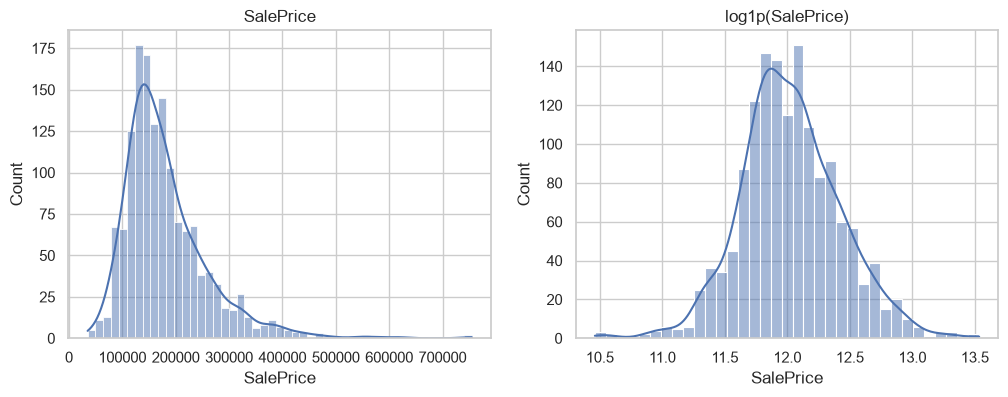

Asimetría SalePrice: 1.88 -> log1p: 0.12
Top correlaciones numéricas con SalePrice:


,r
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534


In [24]:
# Exploración
faltan = X_all.isna().mean().sort_values(ascending=False); display(faltan[faltan > 0].head(10).round(3).to_frame("% faltante"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_raw, kde=True, ax=axes[0]).set_title("SalePrice"); sns.histplot(np.log1p(y_raw), kde=True, ax=axes[1]).set_title("log1p(SalePrice)"); plt.show()
print("Asimetría SalePrice:", round(y_raw.skew(), 2), "-> log1p:", round(np.log1p(y_raw).skew(), 2))
corr_num = pd.concat([X_all[num_cols], y_raw], axis=1).corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
print("Top correlaciones numéricas con SalePrice:"); display(corr_num.head(8).round(3).to_frame("r"))

,RMSE (log) medio,std
Ridge,0.1420,0.0319
Lasso,0.1400,0.0368
Random Forest,0.1467,0.0174
Gradient Boosting,0.1307,0.0201


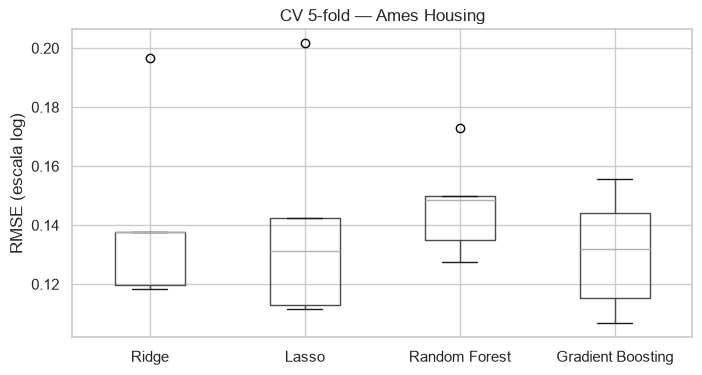

In [25]:
def make_prep(scale=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(num), num_cols),
                              ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                                ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

y = np.log1p(y_raw)
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=RS)
pipes = {
    "Ridge": Pipeline([("prep", make_prep()), ("model", Ridge(alpha=10))]),
    "Lasso": Pipeline([("prep", make_prep()), ("model", Lasso(alpha=0.001, max_iter=20000))]),
    "Random Forest": Pipeline([("prep", make_prep()), ("model", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RS))]),
    "Gradient Boosting": Pipeline([("prep", make_prep()), ("model", GradientBoostingRegressor(random_state=RS))]),
}
cv = KFold(5, shuffle=True, random_state=RS)
cv_res = {n: -cross_val_score(p, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1) for n, p in pipes.items()}
cv_df = pd.DataFrame(cv_res); display(cv_df.agg(["mean", "std"]).T.round(4).rename(columns={"mean": "RMSE (log) medio", "std": "std"}))
cv_df.boxplot(figsize=(8, 4)); plt.ylabel("RMSE (escala log)"); plt.title("CV 5-fold — Ames Housing"); plt.show()

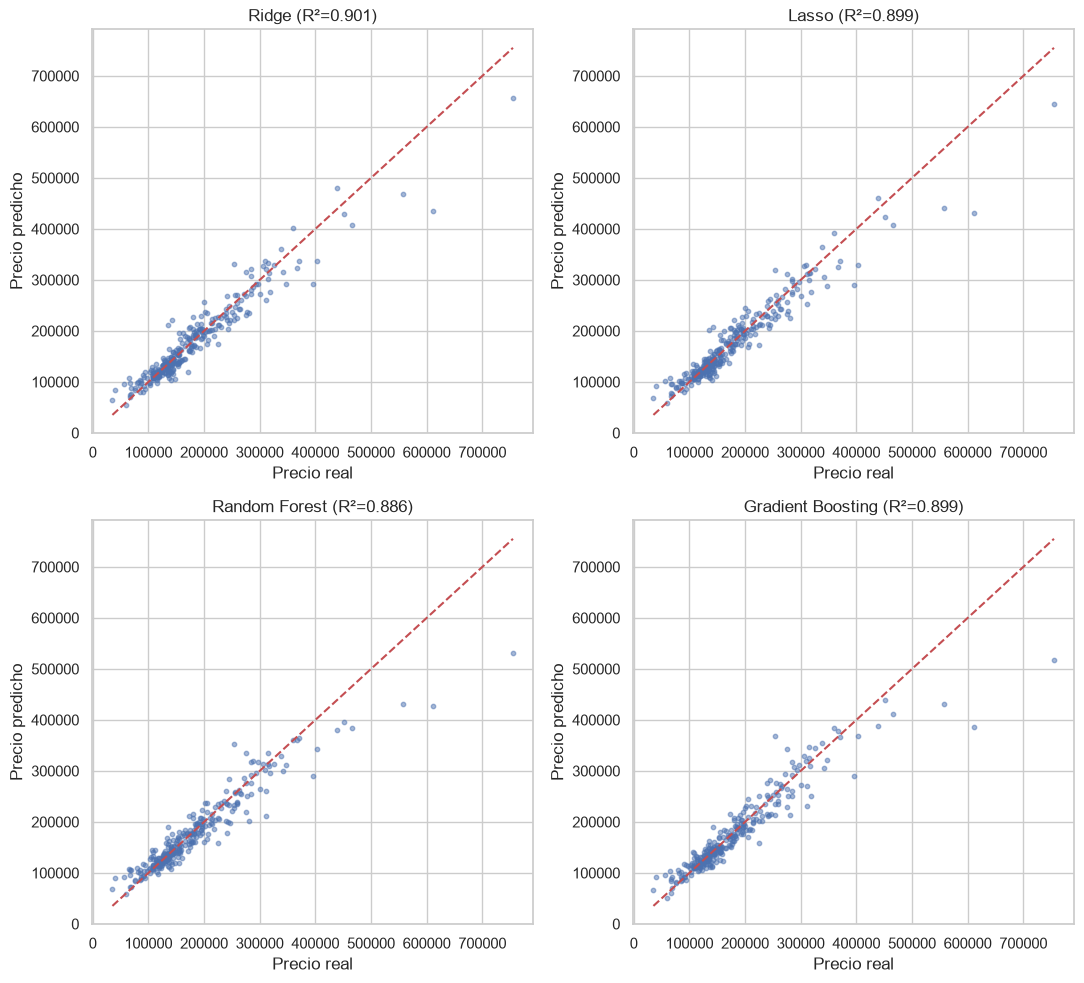

In [26]:
# Predicción vs real (test) para cada modelo
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (n, p) in zip(axes.ravel(), pipes.items()):
    p.fit(Xtr, ytr); pr = p.predict(Xte)
    ax.scatter(np.expm1(yte), np.expm1(pr), s=10, alpha=0.5); lim = [np.expm1(yte).min(), np.expm1(yte).max()]
    ax.plot(lim, lim, "r--"); ax.set_title(f"{n} (R²={r2_score(yte, pr):.3f})"); ax.set_xlabel("Precio real"); ax.set_ylabel("Precio predicho")
plt.tight_layout(); plt.show()

In [27]:
# Tuning del mejor modelo según CV
mejor = cv_df.mean().idxmin(); print("Modelo a afinar:", mejor)
grids = {"Ridge": {"model__alpha": [0.1, 1, 10, 30, 100]},
         "Lasso": {"model__alpha": [0.0003, 0.001, 0.003, 0.01]},
         "Random Forest": {"model__max_depth": [10, 20, None], "model__max_features": ["sqrt", 0.5]},
         "Gradient Boosting": {"model__n_estimators": [200, 400], "model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 4]}}
gs = GridSearchCV(pipes[mejor], grids[mejor], cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(Xtr, ytr)
print("Mejores hiperparámetros:", gs.best_params_, "| RMSE log (CV):", round(-gs.best_score_, 4))
final = gs.best_estimator_; pr = final.predict(Xte)
print("Test — RMSE (log):", round(np.sqrt(mean_squared_error(yte, pr)), 4), "| R²:", round(r2_score(yte, pr), 4))
print("Test — RMSE en dólares:", round(np.sqrt(mean_squared_error(np.expm1(yte), np.expm1(pr))), 0),
      "| MAE en dólares:", round(mean_absolute_error(np.expm1(yte), np.expm1(pr)), 0))

Modelo a afinar: Gradient Boosting
Mejores hiperparámetros: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 400} | RMSE log (CV): 0.1262
Test — RMSE (log): 0.1353 | R²: 0.9019
Test — RMSE en dólares: 29771.0 | MAE en dólares: 16422.0


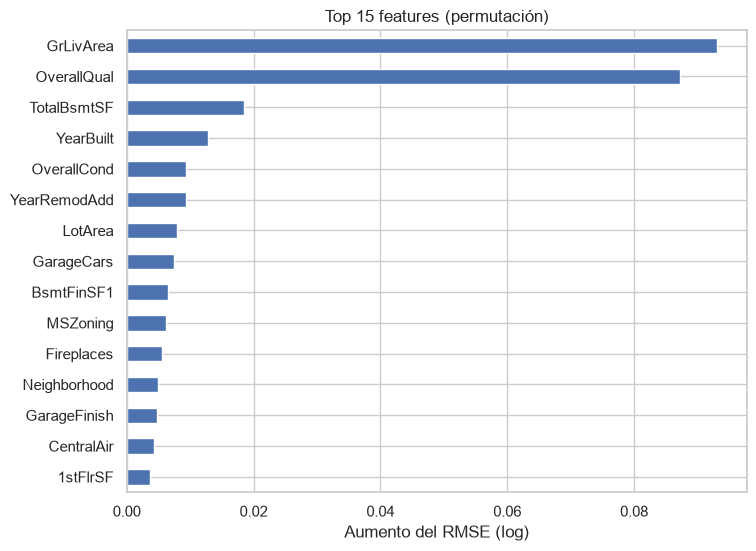

GrLivArea       0.0931
OverallQual     0.0872
TotalBsmtSF     0.0184
YearBuilt       0.0129
OverallCond     0.0093
YearRemodAdd    0.0093
LotArea         0.0079
GarageCars      0.0074
BsmtFinSF1      0.0065
MSZoning        0.0061
dtype: float64


In [28]:
# Interpretación: importancia por permutación sobre las columnas ORIGINALES (el pipeline incluye el preprocesado)
pi = permutation_importance(final, Xte, yte, scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(8, 6), color="#4C72B0"); plt.title("Top 15 features (permutación)"); plt.xlabel("Aumento del RMSE (log)"); plt.show()
print(imp.head(10).round(4))